# Exciton–cavity polaritons planar microcavity

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import numpy as np
from tqdm.auto import tqdm

import microcavity as mc

plt.rcParams.update({
    "figure.dpi": 120, "axes.grid": True, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
})
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)
FIGURE_WIDTH = 7.2
FIGURE_HEIGHT = 3.2

def save_show(fig, filename, dpi=160):
    fig.savefig(
        FIGURE_DIR / filename, dpi=dpi, bbox_inches="tight",
        facecolor="white", pil_kwargs={"optimize": True, "compress_level": 9},
    )
    plt.show()
    plt.close(fig)

def minimum_energy_bins(energies, values, bins):
    block = len(energies) // bins
    usable = block * bins
    energy_bins = energies[:usable].reshape(bins, block).mean(axis=1)
    value_bins = values[:, :usable].reshape(len(values), bins, block).min(axis=2)
    return energy_bins, value_bins

NUMERICAL_GRID_STYLE = {"marker": ".", "markersize": 2.0}

cfg = {
    "n_air": 1.0,
    "n_h": 3.60,
    "n_l": 2.95,
    "n_cavity": 3.60,
    "n_qw": 3.65,
    "energy_zero": 1.450,
    "n_top": 23,
    "n_bottom": 26,
    "qw_thickness": 0.006,
    "exciton_mass_ratio": 0.5,
    "gamma_x": mc.mev(0.25),
    "single_qw_rabi_target": mc.mev(8.0 / np.sqrt(6.0)),
    "energy_min": 1.35,
    "energy_max": 1.55,
    "energy_points": 4001,
    "momentum_min": 0.0,
    "momentum_max": 4.0,
    "momentum_points": 241,
    "bare_map_points": 120000,
    "polariton_map_points": 60000,
    "map_display_rows": 1200,
    "field_dz": 5.0e-4,
    "dbr_cases": [(8, 8), (12, 12), (16, 16), (23, 26)],
    "detunings_mev": [-8.0, -5.8, 0.0, 1.0],
    "position_points": 65,
    "tuning_options": {
        "resonance_half_window": 0.03,
        "resonance_coarse_points": 401,
    },
}


## 1. Materials, geometry, and analytical scalar model

In [2]:
cfg["lambda_zero"] = mc.HC / cfg["energy_zero"]
cfg["d_h"] = cfg["lambda_zero"] / (4.0 * cfg["n_h"])
cfg["d_l"] = cfg["lambda_zero"] / (4.0 * cfg["n_l"])
cfg["cavity_length_initial"] = 2.0 * cfg["lambda_zero"] / cfg["n_cavity"]

energy_grid = np.linspace(cfg["energy_min"], cfg["energy_max"], cfg["energy_points"])
momentum_grid = np.linspace(cfg["momentum_min"], cfg["momentum_max"], cfg["momentum_points"])
exciton_grid = mc.exciton_energy(momentum_grid, cfg["energy_zero"], cfg["exciton_mass_ratio"])
ideal_photon_grid = mc.photon_energy(momentum_grid, cfg["energy_zero"], cfg["n_cavity"])
analytical_lp, analytical_up = mc.polariton_energies(
    ideal_photon_grid, exciton_grid, cfg["single_qw_rabi_target"]
)
hopfield = mc.hopfield_coefficients(
    ideal_photon_grid, exciton_grid, cfg["single_qw_rabi_target"]
)

print(f"lambda_0 = {cfg['lambda_zero'] * 1e3:.3f} nm")
print(f"d_H = {cfg['d_h'] * 1e3:.3f} nm, d_L = {cfg['d_l'] * 1e3:.3f} nm")
print(f"L_C initial = {cfg['cavity_length_initial']:.6f} um")
print(f"ideal photon mass = {mc.photon_mass_ratio(cfg['energy_zero'], cfg['n_cavity']):.4e} m0")


lambda_0 = 855.063 nm
d_H = 59.379 nm, d_L = 72.463 nm
L_C initial = 0.475035 um
ideal photon mass = 3.6775e-05 m0


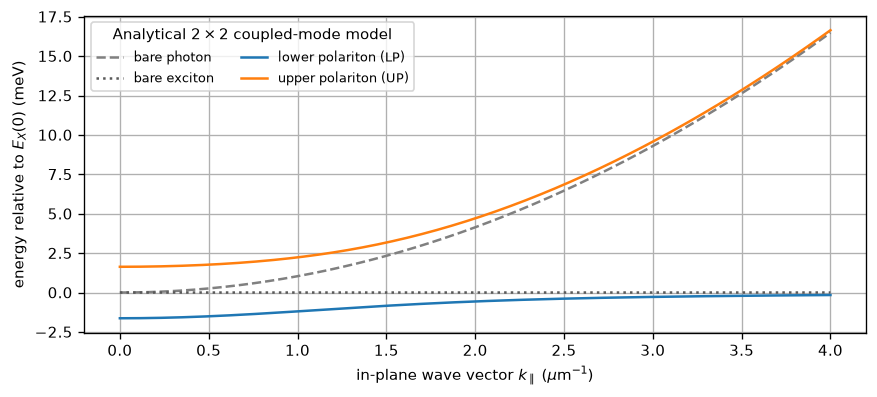

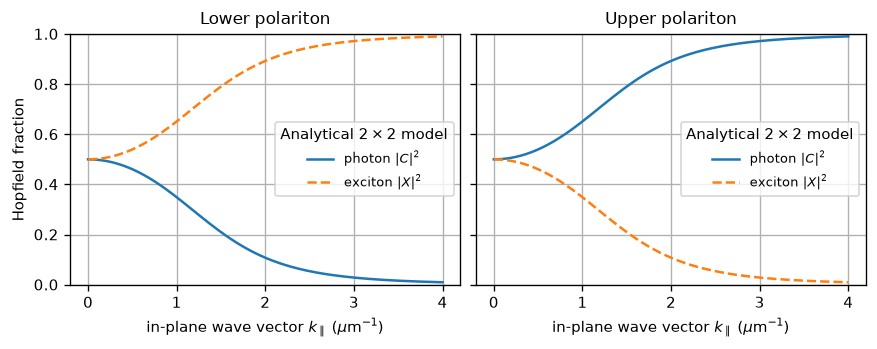

In [3]:
energy_offset = lambda values: mc.to_mev(np.asarray(values) - cfg["energy_zero"])

# 2. Analytical polariton dispersion
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
ax.plot(momentum_grid, energy_offset(ideal_photon_grid), "--", color="0.5", label="bare photon")
ax.plot(momentum_grid, energy_offset(exciton_grid), ":", color="0.35", label="bare exciton")
ax.plot(momentum_grid, energy_offset(analytical_lp), label="lower polariton (LP)")
ax.plot(momentum_grid, energy_offset(analytical_up), label="upper polariton (UP)")
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"energy relative to $E_X(0)$ (meV)",
)
ax.legend(title=r"Analytical $2\times2$ coupled-mode model", ncol=2)
save_show(fig, "02_analytical_polariton_dispersion.png")

# 3. Hopfield coefficients
fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH, 2.8), sharey=True, layout="constrained")
for ax, branch in zip(axes, ("lp", "up")):
    ax.plot(momentum_grid, hopfield[f"photon_{branch}"], label=r"photon $|C|^2$")
    ax.plot(momentum_grid, hopfield[f"exciton_{branch}"], "--", label=r"exciton $|X|^2$")
    branch_name = "Lower polariton" if branch == "lp" else "Upper polariton"
    ax.set(
        xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
        title=branch_name, ylim=(0, 1),
    )
    ax.legend(title=r"Analytical $2\times2$ model")
axes[0].set_ylabel("Hopfield fraction")
save_show(fig, "03_hopfield_coefficients.png")


## 2. Exact DBR structure and passive-QW photon reference

The QW position and passive-index tuning form a small fixed-point problem. We first tune a homogeneous cavity, place the QW at its central antinode, and then iterate passive-QW tuning and antinode reconstruction.

In [4]:
base_geometry = {
    "n_h": cfg["n_h"], "n_l": cfg["n_l"],
    "d_h": cfg["d_h"], "d_l": cfg["d_l"],
    "n_top": cfg["n_top"], "n_bottom": cfg["n_bottom"],
    "n_cavity": cfg["n_cavity"],
}

def qw_spec(z, gamma_0=0.0, enabled=False, name="QW"):
    return {
        "name": name, "z": z, "n": cfg["n_qw"],
        "d": cfg["qw_thickness"], "ex0": cfg["energy_zero"],
        "mass_ratio": cfg["exciton_mass_ratio"],
        "gamma_x": cfg["gamma_x"], "gamma_0": gamma_0,
        "enabled": enabled,
    }

def homogeneous_builder(length):
    return mc.build_microcavity(**base_geometry, cavity_length=length)

def background_builder(length, offset):
    return mc.build_microcavity(
        **base_geometry, cavity_length=length,
        qws=[qw_spec(length / 2.0 + offset)],
    )

baseline = mc.tune_qw_to_central_antinode(
    homogeneous_builder, background_builder, cfg["energy_zero"],
    cfg["cavity_length_initial"],
    n_left=cfg["n_air"], n_right=cfg["n_air"],
    minimum_peak_separation=cfg["lambda_zero"] / (4.0 * cfg["n_cavity"]),
    dz=cfg["field_dz"], tuning_options=cfg["tuning_options"],
)
cavity_length = baseline["length"]
qw_offset = baseline["qw_offset"]
qw_position = baseline["qw_position"]
background_layers = baseline["layers"]
print(f"tuned L_C = {cavity_length:.9f} um")
print(f"QW centre = {qw_position:.9f} um, centre offset = {qw_offset * 1e3:.3f} nm")


tuned L_C = 0.474867789 um
QW centre = 0.237416272 um, centre offset = -0.018 nm


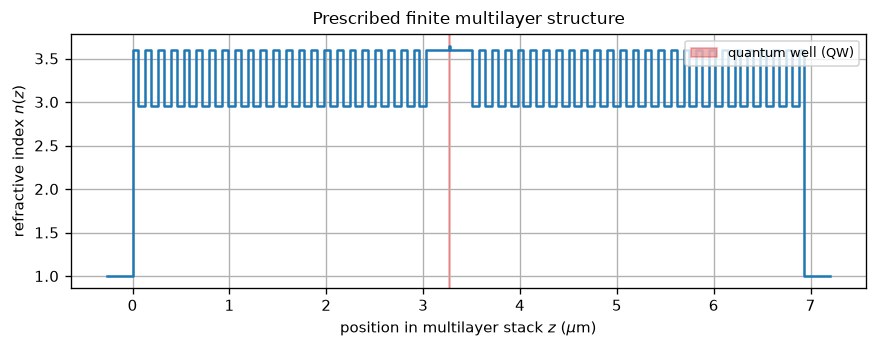

In [5]:
exterior_width = 2.0 * (cfg["d_h"] + cfg["d_l"])
z_index, n_index = mc.index_profile(
    background_layers, n_left=cfg["n_air"], n_right=cfg["n_air"],
    exterior_width=exterior_width,
)
field = baseline["field"]
antinodes = mc.find_field_antinodes(
    field["z"], field["intensity"],
    minimum_separation=cfg["lambda_zero"] / (4.0 * cfg["n_cavity"]),
)
# 1. Refractive-index profile
top_dbr_width = mc.total_thickness(background_layers, region="top_dbr")
qw_global_position = top_dbr_width + qw_position
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 2.8), layout="constrained")
ax.plot(z_index, n_index)
ax.axvspan(
    qw_global_position - cfg["qw_thickness"] / 2.0,
    qw_global_position + cfg["qw_thickness"] / 2.0,
    color="tab:red", alpha=0.35, label="quantum well (QW)",
)
ax.set(
    xlabel=r"position in multilayer stack $z$ ($\mu$m)",
    ylabel=r"refractive index $n(z)$",
    title="Prescribed finite multilayer structure",
)
ax.legend(loc="upper right")
save_show(fig, "01_refractive_index_profile.png")


## 3. Bare finite-DBR cavity and numerical checks

In [6]:
checks = mc.basic_tmm_checks(
    background_layers, energy_grid,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
    n_test_a=cfg["n_h"], n_test_b=cfg["n_l"],
)
assert checks["zero_thickness_error"] < 1e-14
assert checks["interface_inverse_error"] < 1e-12
assert checks["energy_conservation_error"] < 1e-9
assert checks["normal_incidence_te_tm_error"] < 1e-10
print(checks)

bare_pole = mc.solve_bare_cavity_pole(
    background_layers, cfg["energy_zero"],
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
print("bare pole:", bare_pole["pole"])
print(f"bare linewidth = {mc.to_mev(mc.linewidth_from_pole(bare_pole['pole'])):.6f} meV")
print(f"bare Q = {mc.quality_factor_from_pole(bare_pole['pole']):.1f}")

bare_poles = np.empty(momentum_grid.shape, dtype=np.complex128)
bare_pole_residuals = np.full(momentum_grid.shape, np.nan)
bare_poles[0] = bare_pole["pole"]
bare_pole_residuals[0] = bare_pole["residual"]
for index, momentum in enumerate(
    tqdm(momentum_grid[1:], desc="bare complex pole"), start=1,
):
    matrix = lambda energy, k=float(momentum): mc.stack_matrix(
        energy, k, "TE", background_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    result = mc.solve_complex_pole(matrix, bare_poles[index - 1])
    if not result["success"]:
        result = mc.solve_bare_cavity_pole(
            background_layers, bare_poles[index - 1].real,
            n_left=cfg["n_air"], n_right=cfg["n_air"],
            polarization="TE", k_parallel=float(momentum),
            minimum_half_window=0.003,
        )
    bare_poles[index] = result["pole"]
    bare_pole_residuals[index] = result["residual"]
assert np.all(np.isfinite(bare_poles))
bare_branch = bare_poles.real
bare_map_energy = np.linspace(1.43, 1.49, cfg["bare_map_points"])
bare_reflectivity_te = mc.reflectivity_map(
    bare_map_energy, momentum_grid, "TE", background_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
print(f"bare-map step = {mc.to_mev(bare_map_energy[1] - bare_map_energy[0]):.6f} meV")
mass_fit = mc.fit_parabolic_photon_mass(momentum_grid, bare_branch, maximum_momentum=1.0)
print("TMM photon mass / m0:", mass_fit["mass_ratio"])


{'zero_thickness_error': 0.0, 'interface_inverse_error': 4.440892098500626e-16, 'energy_conservation_error': 9.139800027924139e-12, 'normal_incidence_te_tm_error': 4.401201625370277e-12}
bare pole: (1.450000002056547-2.0574085454708884e-06j)
bare linewidth = 0.004115 meV
bare Q = 352385.0


bare complex pole:   0%|          | 0/240 [00:00<?, ?it/s]

TE reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

bare-map step = 0.000500 meV
TMM photon mass / m0: 3.2199339702687076e-05


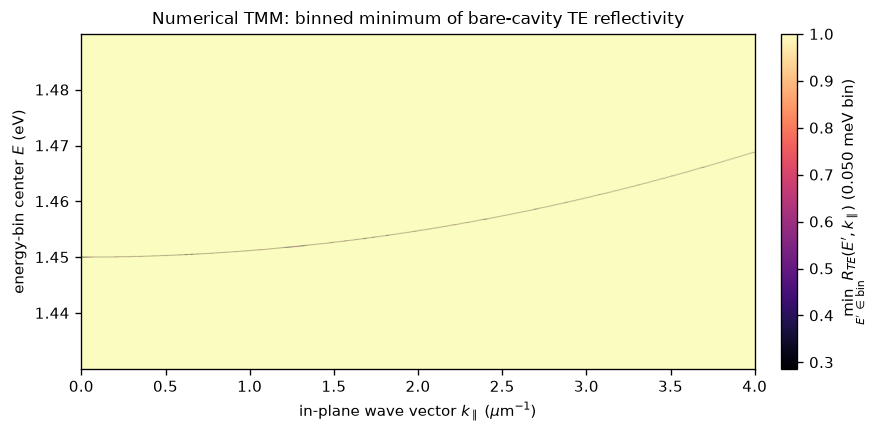

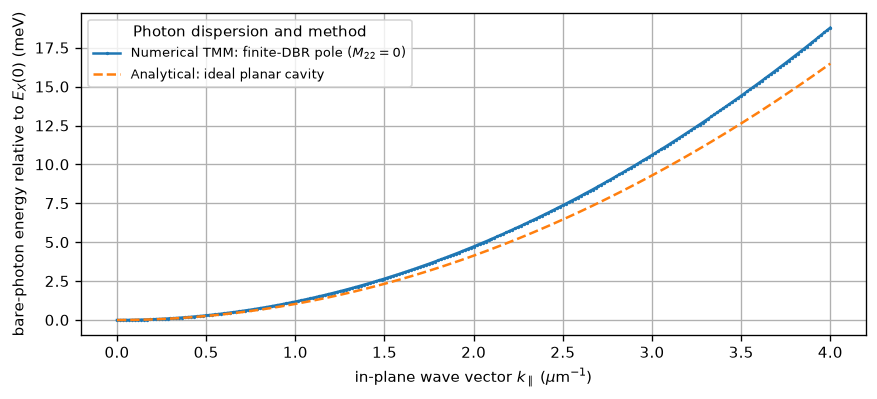

In [7]:
# 4. Bare-cavity TE reflectivity map
bare_display_energy, bare_display_values = minimum_energy_bins(
    bare_map_energy, bare_reflectivity_te, cfg["map_display_rows"]
)
bare_display_bin_mev = mc.to_mev((bare_map_energy[-1] - bare_map_energy[0]) / cfg["map_display_rows"])
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 3.5), layout="constrained")
image = ax.imshow(
    bare_display_values.T, origin="lower", aspect="auto",
    extent=(momentum_grid[0], momentum_grid[-1], bare_display_energy[0], bare_display_energy[-1]),
    interpolation="bilinear", cmap="magma",
    vmin=np.nanmin(bare_reflectivity_te), vmax=1.0,
)
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"energy-bin center $E$ (eV)",
    title="Numerical TMM: binned minimum of bare-cavity TE reflectivity",
)
ax.grid(False)
fig.colorbar(
    image, ax=ax,
    label=rf"$\min_{{E'\,\in\,\mathrm{{bin}}}} R_{{TE}}(E',k_\parallel)$ ({bare_display_bin_mev:.3f} meV bin)",
    pad=0.02,
)
save_show(fig, "04_bare_cavity_reflectivity_map.png", dpi=300)
del bare_reflectivity_te

# 5. Finite-DBR photon pole versus the ideal planar-cavity dispersion
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
ax.plot(momentum_grid, energy_offset(bare_branch), label=r"Numerical TMM: finite-DBR pole ($M_{22}=0$)", **NUMERICAL_GRID_STYLE)
ax.plot(momentum_grid, energy_offset(ideal_photon_grid), "--", label="Analytical: ideal planar cavity")
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"bare-photon energy relative to $E_X(0)$ (meV)",
)
ax.legend(title="Photon dispersion and method", ncol=1)
save_show(fig, "05_bare_photon_dispersion_comparison.png")


## 4. Single-QW calibration, reflectivity maps, and complex poles

In [8]:
def active_layers(gamma_0, polarization_position=qw_position):
    return mc.build_microcavity(
        **base_geometry, cavity_length=cavity_length,
        qws=[qw_spec(polarization_position, gamma_0=gamma_0, enabled=True)],
    )

def calibration_matrix_builder(gamma_0):
    layers = active_layers(gamma_0)
    return lambda energy: mc.stack_matrix(
        energy, 0.0, "TE", layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )

calibration = mc.calibrate_radiative_width(
    calibration_matrix_builder, cfg["single_qw_rabi_target"],
    cfg["energy_zero"], bare_pole["pole"], cfg["gamma_x"],
)
gamma_0 = calibration["gamma_0"]
polariton_layers = active_layers(gamma_0)
assert abs(calibration["splitting"] - cfg["single_qw_rabi_target"]) < 1e-6
print(f"calibrated Gamma_0 = {mc.to_mev(gamma_0):.6f} meV")
print(f"pole splitting = {mc.to_mev(calibration['splitting']):.6f} meV")


calibrated Gamma_0 = 0.024474 meV
pole splitting = 3.265986 meV


In [9]:
polariton_map_energy = np.linspace(1.44, 1.47, cfg["polariton_map_points"])
polariton_reflectivity_te = mc.reflectivity_map(
    polariton_map_energy, momentum_grid, "TE", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"], progress=True,
)
normal_te = mc.reflectivity(
    energy_grid, 0.0, "TE", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
normal_tm = mc.reflectivity(
    energy_grid, 0.0, "TM", polariton_layers,
    n_left=cfg["n_air"], n_right=cfg["n_air"],
)
assert np.max(np.abs(normal_te - normal_tm)) < 1e-10
print(f"polariton-map step = {mc.to_mev(polariton_map_energy[1] - polariton_map_energy[0]):.6f} meV")
scalar_lp, scalar_up = mc.polariton_energies(
    bare_branch, exciton_grid, cfg["single_qw_rabi_target"]
)

def spectrum(energy, momentum, polarization):
    return float(mc.reflectivity(
        energy, momentum, polarization, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    ))

dips_te = mc.trace_reflectivity_branches(
    momentum_grid, scalar_lp, scalar_up,
    lambda energy, momentum: spectrum(energy, momentum, "TE"),
)
dips_tm = mc.trace_reflectivity_branches(
    momentum_grid, scalar_lp, scalar_up,
    lambda energy, momentum: spectrum(energy, momentum, "TM"),
)

def pole_matrix_factory(polarization):
    return lambda momentum: lambda energy: mc.stack_matrix(
        energy, momentum, polarization, polariton_layers,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
    )

def oscillator_prediction(momentum):
    cavity_pole = complex(
        np.interp(momentum, momentum_grid, bare_poles.real),
        np.interp(momentum, momentum_grid, bare_poles.imag),
    )
    exciton_value = float(mc.exciton_energy(momentum, cfg["energy_zero"], cfg["exciton_mass_ratio"]))
    return mc.complex_coupled_oscillator_eigenvalues(
        cavity_pole.real, exciton_value, cfg["single_qw_rabi_target"],
        mc.linewidth_from_pole(cavity_pole), 2.0 * cfg["gamma_x"],
    )

poles_te = mc.trace_two_complex_poles(
    momentum_grid, pole_matrix_factory("TE"), calibration["poles"],
    fallback_predictions=oscillator_prediction, progress=True,
)
poles_tm = mc.trace_two_complex_poles(
    momentum_grid, pole_matrix_factory("TM"), calibration["poles"],
    fallback_predictions=oscillator_prediction, progress=True,
)
assert np.all(poles_te["success"]) and np.all(poles_tm["success"])


TE reflectivity:   0%|          | 0/241 [00:00<?, ?it/s]

polariton-map step = 0.000500 meV


complex poles:   0%|          | 0/241 [00:00<?, ?it/s]

complex poles:   0%|          | 0/241 [00:00<?, ?it/s]

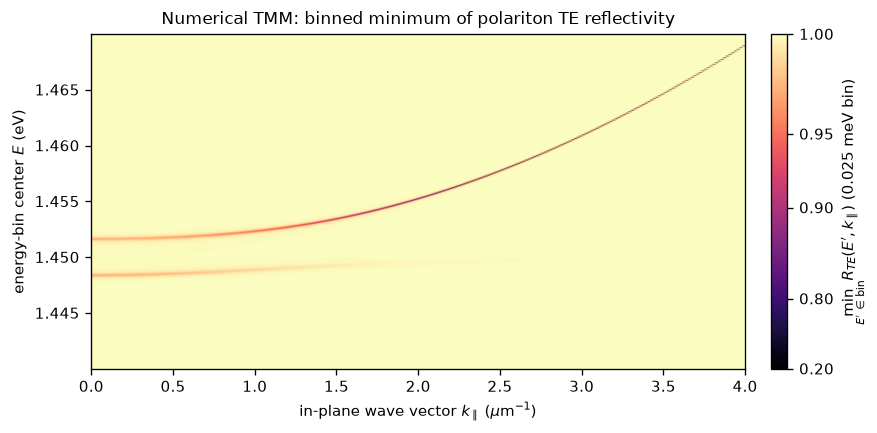

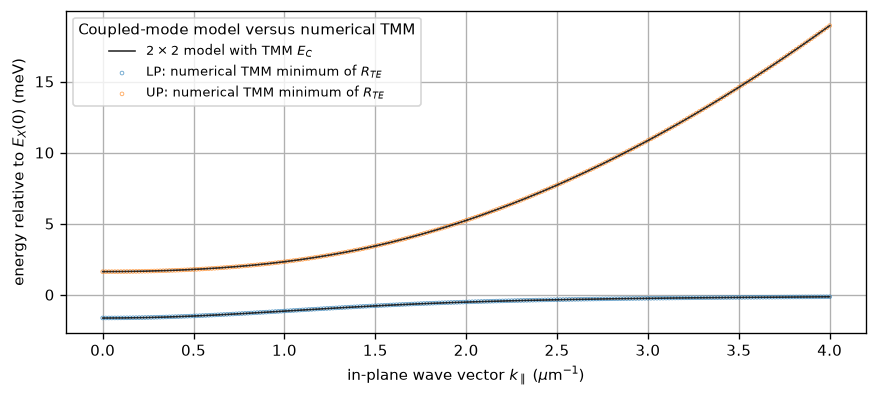

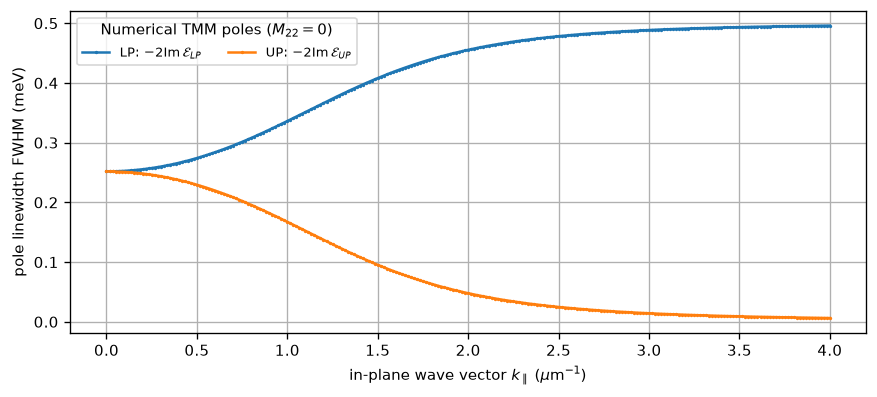

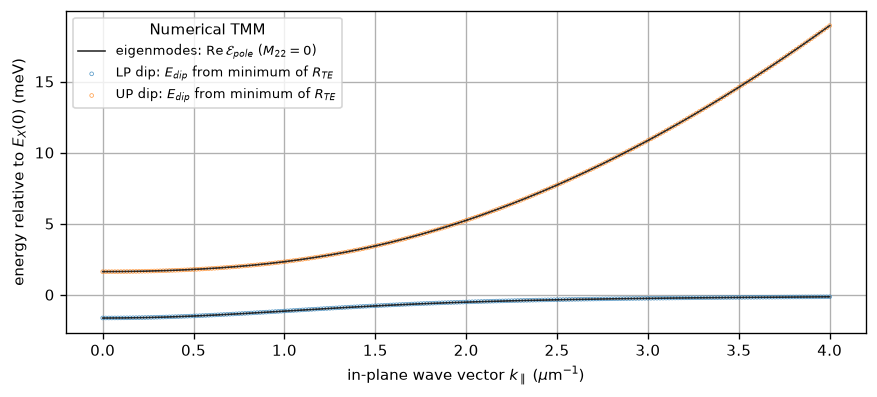

In [10]:
# 6. TE polariton reflectivity map
polariton_display_energy, polariton_display_values = minimum_energy_bins(
    polariton_map_energy, polariton_reflectivity_te, cfg["map_display_rows"]
)
polariton_display_bin_mev = mc.to_mev((polariton_map_energy[-1] - polariton_map_energy[0]) / cfg["map_display_rows"])
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, 3.5), layout="constrained")
image = ax.imshow(
    polariton_display_values.T, origin="lower", aspect="auto",
    extent=(momentum_grid[0], momentum_grid[-1], polariton_display_energy[0], polariton_display_energy[-1]),
    interpolation="bilinear", cmap="magma",
    norm=PowerNorm(gamma=6.0, vmin=np.nanmin(polariton_reflectivity_te), vmax=1.0),
)
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"energy-bin center $E$ (eV)",
    title="Numerical TMM: binned minimum of polariton TE reflectivity",
)
ax.grid(False)
colorbar = fig.colorbar(
    image, ax=ax,
    label=rf"$\min_{{E'\,\in\,\mathrm{{bin}}}} R_{{TE}}(E',k_\parallel)$ ({polariton_display_bin_mev:.3f} meV bin)",
    pad=0.02,
)
colorbar.set_ticks([0.2, 0.8, 0.9, 0.95, 1.0])
save_show(fig, "06_polariton_reflectivity_map_te.png", dpi=300)
del polariton_reflectivity_te

# 7. Reflectivity branches versus the real 2x2 model with E_C = Re(E_C^bg)
resolved_te = dips_te["resolved"]
resolved_indices = np.flatnonzero(resolved_te)
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
model_style = {"color": "0.05", "lw": 1.0, "alpha": 0.85, "zorder": 3}
ax.plot(momentum_grid, energy_offset(scalar_lp), label=r"$2\times2$ model with TMM $E_C$", **model_style)
ax.plot(momentum_grid, energy_offset(scalar_up), label="_nolegend_", **model_style)
ax.scatter(momentum_grid[resolved_indices], energy_offset(dips_te["lp"][resolved_indices]), s=5, facecolors="none", edgecolors="C0", linewidths=0.45, alpha=0.75, zorder=2, label=r"LP: numerical TMM minimum of $R_{TE}$")
ax.scatter(momentum_grid[resolved_indices], energy_offset(dips_te["up"][resolved_indices]), s=5, facecolors="none", edgecolors="C1", linewidths=0.45, alpha=0.75, zorder=2, label=r"UP: numerical TMM minimum of $R_{TE}$")
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"energy relative to $E_X(0)$ (meV)",
)
ax.legend(title="Coupled-mode model versus numerical TMM", ncol=1, loc="upper left")
save_show(fig, "07_polariton_tmm_vs_2x2.png")

# 11. Polariton linewidths from the imaginary parts of the TE poles
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
ax.plot(momentum_grid, mc.to_mev(mc.linewidth_from_pole(poles_te["lp"])), label=r"LP: $-2\operatorname{Im}\mathcal{E}_{LP}$", **NUMERICAL_GRID_STYLE)
ax.plot(momentum_grid, mc.to_mev(mc.linewidth_from_pole(poles_te["up"])), label=r"UP: $-2\operatorname{Im}\mathcal{E}_{UP}$", **NUMERICAL_GRID_STYLE)
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel="pole linewidth FWHM (meV)",
)
ax.legend(title=r"Numerical TMM poles ($M_{22}=0$)", ncol=2)
save_show(fig, "11_polariton_linewidths.png")

# 12. Reflectivity minima versus complex-pole energies
fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
pole_style = {"color": "0.05", "lw": 1.0, "alpha": 0.85, "zorder": 3}
ax.plot(momentum_grid, energy_offset(poles_te["lp"].real), label=r"eigenmodes: $\operatorname{Re}\mathcal{E}_{pole}$ ($M_{22}=0$)", **pole_style)
ax.plot(momentum_grid, energy_offset(poles_te["up"].real), label="_nolegend_", **pole_style)
ax.scatter(momentum_grid[resolved_indices], energy_offset(dips_te["lp"][resolved_indices]), s=5, facecolors="none", edgecolors="C0", linewidths=0.45, alpha=0.75, zorder=2, label=r"LP dip: $E_{dip}$ from minimum of $R_{TE}$")
ax.scatter(momentum_grid[resolved_indices], energy_offset(dips_te["up"][resolved_indices]), s=5, facecolors="none", edgecolors="C1", linewidths=0.45, alpha=0.75, zorder=2, label=r"UP dip: $E_{dip}$ from minimum of $R_{TE}$")
ax.set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel=r"energy relative to $E_X(0)$ (meV)",
)
ax.legend(title="Numerical TMM", ncol=1, loc="upper left")
save_show(fig, "12_reflectivity_dips_vs_poles.png")


## 5. DBR-number sweep

DBR sweep:   0%|          | 0/4 [00:00<?, ?it/s]

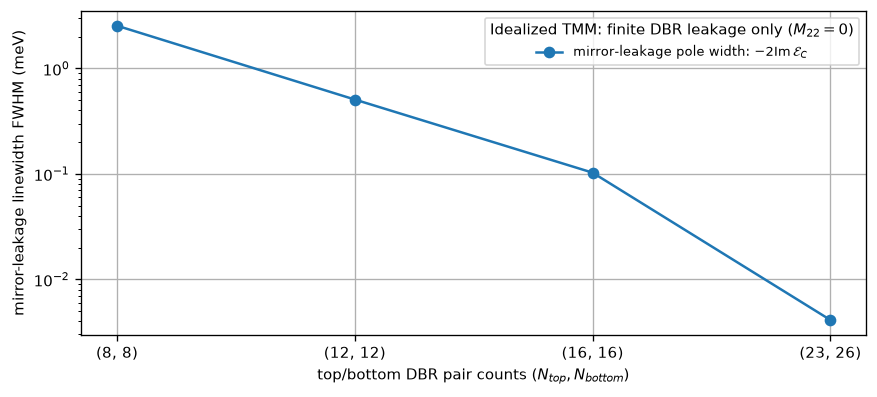

In [11]:
dbr_results = []
for n_top, n_bottom in tqdm(cfg["dbr_cases"], desc="DBR sweep"):
    geometry = dict(base_geometry, n_top=n_top, n_bottom=n_bottom)
    def case_builder(length, geometry=geometry):
        return mc.build_microcavity(
            **geometry, cavity_length=length,
            qws=[qw_spec(length / 2.0 + qw_offset)],
        )
    tuned = mc.tune_cavity_length(
        case_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
        **cfg["tuning_options"],
    )
    layers = case_builder(tuned["length"])
    result = mc.solve_bare_cavity_pole(
        layers, cfg["energy_zero"], n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    dbr_results.append({
        "n_top": n_top, "n_bottom": n_bottom, "length": tuned["length"],
        "pole": result["pole"], "linewidth": mc.linewidth_from_pole(result["pole"]),
    })
dbr_linewidths = np.array([item["linewidth"] for item in dbr_results])
assert np.all(np.diff(dbr_linewidths) < 0.0)

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
dbr_labels = [f"({item['n_top']}, {item['n_bottom']})" for item in dbr_results]
ax.semilogy(
    dbr_labels, mc.to_mev(dbr_linewidths), "o-",
    label=r"mirror-leakage pole width: $-2\operatorname{Im}\mathcal{E}_C$",
)
ax.set(
    xlabel=r"top/bottom DBR pair counts $(N_{top},N_{bottom})$",
    ylabel="mirror-leakage linewidth FWHM (meV)",
)
ax.legend(title=r"Idealized TMM: finite DBR leakage only ($M_{22}=0$)")
save_show(fig, "09_dbr_linewidth_sweep.png")


## 6. QW-position sweep at fixed bare detuning

QW position:   0%|          | 0/65 [00:00<?, ?it/s]

QW-position step = 1.799 nm
resolved bright doublets = 65/65


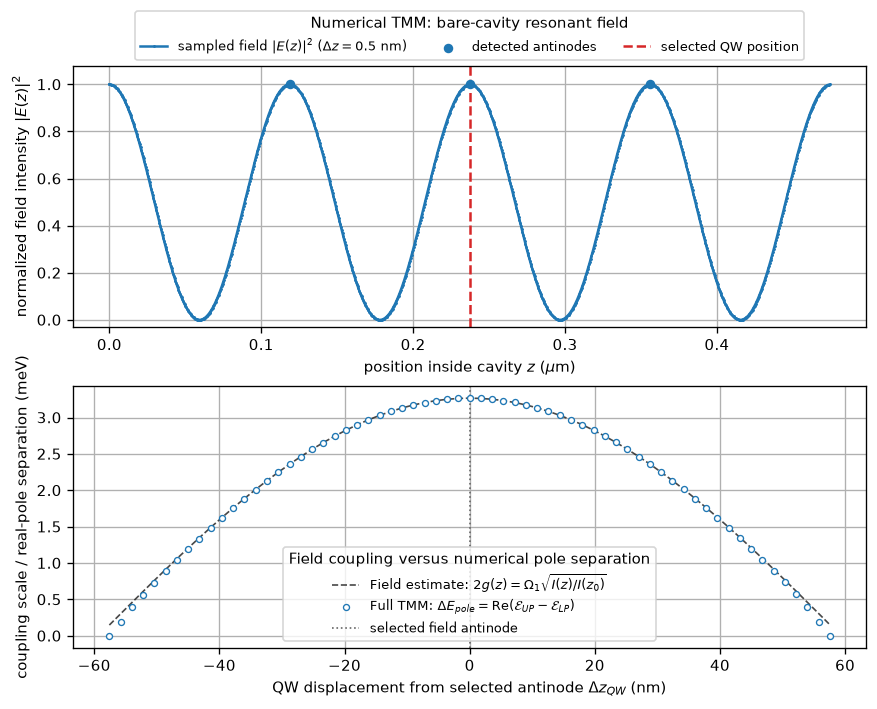

In [12]:
node_distance = cfg["lambda_zero"] / (4.0 * cfg["n_cavity"])
position_edges = np.linspace(-node_distance, node_distance, cfg["position_points"] + 2)
position_offsets = position_edges[1:-1]  # exclude the exact nodes where the bright-pole doublet coalesces
position_splittings = np.full(position_offsets.shape, np.nan)
position_lengths = np.full(position_offsets.shape, np.nan)
position_order = np.argsort(np.abs(position_offsets))
previous_position_poles = list(calibration["poles"])
position_average_imag = 0.5 * (bare_pole["pole"].imag - cfg["gamma_x"])
position_fallback_seeds = [
    complex(cfg["energy_zero"] + shift, imaginary_part)
    for imaginary_part in (bare_pole["pole"].imag, -0.9 * cfg["gamma_x"], position_average_imag)
    for shift in np.linspace(-1.25 * cfg["single_qw_rabi_target"], 1.25 * cfg["single_qw_rabi_target"], 17)
]
for index in tqdm(position_order, desc="QW position"):
    displacement = position_offsets[index]
    fixed_offset = qw_offset + displacement
    def passive_builder(length, fixed_offset=fixed_offset):
        return mc.build_microcavity(
            **base_geometry, cavity_length=length,
            qws=[qw_spec(length / 2.0 + fixed_offset)],
        )
    tuned = mc.tune_cavity_length(
        passive_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"],
        **cfg["tuning_options"],
    )
    position_lengths[index] = tuned["length"]
    active = mc.build_microcavity(
        **base_geometry, cavity_length=tuned["length"],
        qws=[qw_spec(tuned["length"] / 2.0 + fixed_offset, gamma_0=gamma_0, enabled=True)],
    )
    matrix = lambda energy, active=active: mc.stack_matrix(
        energy, 0.0, "TE", active, n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    seeds = previous_position_poles + list(calibration["poles"]) + list(oscillator_prediction(0.0))
    found = mc.discover_complex_poles(matrix, seeds, real_window=(1.43, 1.47), uniqueness_tolerance=1e-8)
    if len(found) < 2:
        found = mc.discover_complex_poles(
            matrix, seeds + position_fallback_seeds,
            real_window=(1.43, 1.47), uniqueness_tolerance=1e-8,
        )
    if len(found) >= 2:
        position_splittings[index] = found[-1]["pole"].real - found[0]["pole"].real
        previous_position_poles = [found[0]["pole"], found[-1]["pole"]]
print(f"QW-position step = {np.diff(position_offsets)[0] * 1e3:.3f} nm")
print(f"resolved bright doublets = {np.count_nonzero(np.isfinite(position_splittings))}/{len(position_offsets)}")

# 8. Bare-cavity field and position-dependent exciton--photon coupling
valid_positions = np.isfinite(position_splittings)
reference_index = int(np.argmin(np.abs(position_offsets)))
reference_intensity = float(np.interp(qw_position, field["z"], field["intensity"]))
position_intensities = np.interp(
    qw_position + position_offsets, field["z"], field["intensity"],
)
field_coupling_scale = cfg["single_qw_rabi_target"] * np.sqrt(
    np.clip(position_intensities / reference_intensity, 0.0, None)
)
assert abs(position_offsets[reference_index]) < 1e-12
assert np.isclose(
    field_coupling_scale[reference_index], position_splittings[reference_index],
)
field_step_nm = np.median(np.diff(field["z"])) * 1e3
fig, axes = plt.subplots(2, 1, figsize=(FIGURE_WIDTH, 5.8), layout="constrained")
axes[0].plot(
    field["z"], field["intensity"], marker=".", markersize=1.5,
    label=rf"sampled field $|E(z)|^2$ ($\Delta z={field_step_nm:.1f}$ nm)",
)
axes[0].scatter(
    antinodes["z"], antinodes["intensity"], s=22, zorder=3,
    label="detected antinodes",
)
axes[0].axvline(qw_position, color="tab:red", ls="--", label="selected QW position")
axes[0].set(
    xlabel=r"position inside cavity $z$ ($\mu$m)",
    ylabel=r"normalized field intensity $|E(z)|^2$", ylim=(-0.03, 1.08),
)
axes[0].legend(
    title="Numerical TMM: bare-cavity resonant field", ncol=3,
    loc="lower center", bbox_to_anchor=(0.5, 1.02), borderaxespad=0.0,
)
axes[1].plot(
    position_offsets * 1e3, mc.to_mev(field_coupling_scale), "--",
    color="0.1", lw=1.0, alpha=0.8, zorder=2,
    label=r"Field estimate: $2g(z)=\Omega_1\sqrt{I(z)/I(z_0)}$",
)
axes[1].scatter(
    position_offsets[valid_positions] * 1e3, mc.to_mev(position_splittings[valid_positions]),
    s=13, facecolors="white", edgecolors="C0", linewidths=0.8, zorder=3,
    label=r"Full TMM: $\Delta E_{pole}=\operatorname{Re}(\mathcal{E}_{UP}-\mathcal{E}_{LP})$",
)
if np.any(~valid_positions):
    axes[1].scatter(
        position_offsets[~valid_positions] * 1e3, np.zeros(np.count_nonzero(~valid_positions)),
        marker="x", color="tab:red", zorder=3, label="single/coalesced bright pole",
    )
axes[1].axvline(0.0, color="0.4", ls=":", lw=1.0, label="selected field antinode")
axes[1].set(
    xlabel=r"QW displacement from selected antinode $\Delta z_{QW}$ (nm)",
    ylabel="coupling scale / real-pole separation (meV)",
)
axes[1].legend(title="Field coupling versus numerical pole separation")
save_show(fig, "08_qw_position_coupling.png")


## 7. TE–TM splitting

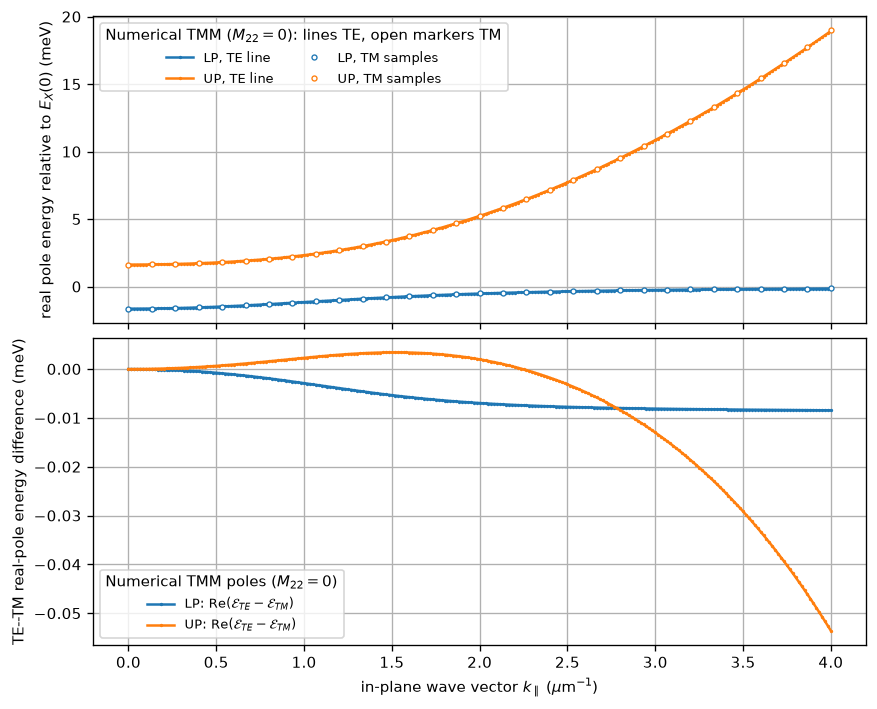

In [13]:
# 10. TE and TM polariton branches and their splitting
te_tm_lp = mc.to_mev(poles_te["lp"].real - poles_tm["lp"].real)
te_tm_up = mc.to_mev(poles_te["up"].real - poles_tm["up"].real)
assert abs(te_tm_lp[0]) < 1e-7 and abs(te_tm_up[0]) < 1e-7
fig, axes = plt.subplots(2, 1, figsize=(FIGURE_WIDTH, 5.8), sharex=True, layout="constrained")
tm_display_indices = np.unique(np.r_[np.arange(0, len(momentum_grid), 8), len(momentum_grid) - 1])
axes[0].plot(momentum_grid, energy_offset(poles_te["lp"].real), color="C0", label="LP, TE line", **NUMERICAL_GRID_STYLE)
axes[0].plot(momentum_grid, energy_offset(poles_te["up"].real), color="C1", label="UP, TE line", **NUMERICAL_GRID_STYLE)
axes[0].plot(
    momentum_grid[tm_display_indices], energy_offset(poles_tm["lp"].real[tm_display_indices]),
    ls="none", marker="o", ms=3.0, mfc="white", mec="C0", mew=0.8, zorder=3,
    label="LP, TM samples",
)
axes[0].plot(
    momentum_grid[tm_display_indices], energy_offset(poles_tm["up"].real[tm_display_indices]),
    ls="none", marker="o", ms=3.0, mfc="white", mec="C1", mew=0.8, zorder=3,
    label="UP, TM samples",
)
axes[0].set(ylabel=r"real pole energy relative to $E_X(0)$ (meV)")
axes[0].legend(title=r"Numerical TMM ($M_{22}=0$): lines TE, open markers TM", ncol=2)
axes[1].plot(momentum_grid, te_tm_lp, label=r"LP: $\operatorname{Re}(\mathcal{E}_{TE}-\mathcal{E}_{TM})$", **NUMERICAL_GRID_STYLE)
axes[1].plot(momentum_grid, te_tm_up, label=r"UP: $\operatorname{Re}(\mathcal{E}_{TE}-\mathcal{E}_{TM})$", **NUMERICAL_GRID_STYLE)
axes[1].set(
    xlabel=r"in-plane wave vector $k_\parallel$ ($\mu$m$^{-1}$)",
    ylabel="TE--TM real-pole energy difference (meV)",
)
axes[1].legend(title=r"Numerical TMM poles ($M_{22}=0$)")
save_show(fig, "10_te_tm_polariton_splitting.png")


## 8. Effective multiple-QW extension

Three effective doublet sheets are placed at the three strongest detected antinodes. Each block replaces 6 nm of GaAs and carries twice the calibrated single-QW radiative parameter. Bright LP/UP are the outer complex poles; intermediate dark or weakly bright roots are retained only as diagnostics.

six-QW effective splitting = 8.018 meV


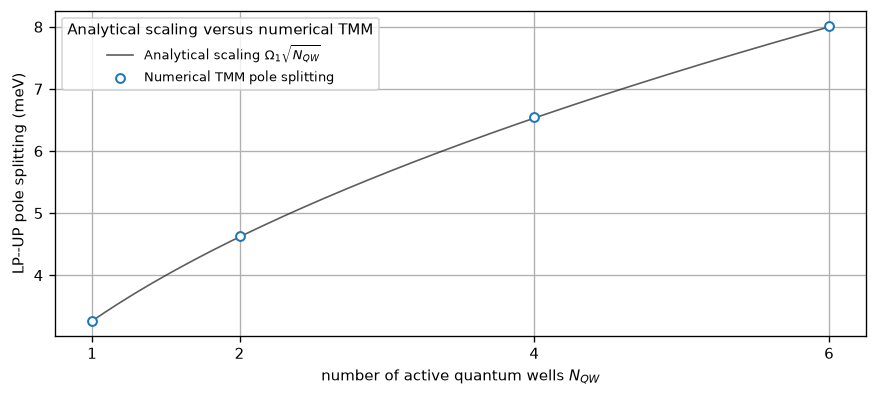

In [14]:
selected_antinodes = mc.select_strongest_antinodes(
    antinodes["z"], antinodes["intensity"], 3, cavity_length=cavity_length,
)
doublet_offsets = selected_antinodes - cavity_length / 2.0

def solve_effective_doublets(count):
    chosen_offsets = doublet_offsets[np.argsort(np.abs(doublet_offsets))[:count]]
    def passive_builder(length):
        qws = [qw_spec(length / 2.0 + offset, name=f"doublet_{i+1}") for i, offset in enumerate(chosen_offsets)]
        return mc.build_microcavity(**base_geometry, cavity_length=length, qws=qws)
    tuned = mc.tune_cavity_length(
        passive_builder, cfg["energy_zero"], cavity_length,
        n_left=cfg["n_air"], n_right=cfg["n_air"], **cfg["tuning_options"],
    )
    qws = [
        qw_spec(tuned["length"] / 2.0 + offset, gamma_0=2.0 * gamma_0, enabled=True, name=f"doublet_{i+1}")
        for i, offset in enumerate(chosen_offsets)
    ]
    layers = mc.build_microcavity(**base_geometry, cavity_length=tuned["length"], qws=qws)
    matrix = lambda energy: mc.stack_matrix(
        energy, 0.0, "TE", layers, n_left=cfg["n_air"], n_right=cfg["n_air"],
    )
    splitting_guess = cfg["single_qw_rabi_target"] * np.sqrt(2.0 * count)
    average_imag = 0.5 * (bare_pole["pole"].imag - cfg["gamma_x"])
    shifts = np.linspace(-1.25 * splitting_guess, 1.25 * splitting_guess, 11)
    seeds = [complex(cfg["energy_zero"] + shift, average_imag) for shift in shifts if abs(shift) > 1e-9]
    found = mc.discover_complex_poles(matrix, seeds, real_window=(1.42, 1.48), uniqueness_tolerance=1e-8)
    if len(found) < 2:
        raise RuntimeError(f"could not resolve bright poles for {count} effective doublets")
    return {
        "count": count, "active_qws": 2 * count, "length": tuned["length"],
        "all_poles": np.array([item["pole"] for item in found]),
        "lp": found[0]["pole"], "up": found[-1]["pole"],
        "splitting": found[-1]["pole"].real - found[0]["pole"].real,
    }

multiple_qw_results = [solve_effective_doublets(count) for count in (1, 2, 3)]
active_qws = np.array([1] + [item["active_qws"] for item in multiple_qw_results])
collective_splittings = np.array([calibration["splitting"]] + [item["splitting"] for item in multiple_qw_results])
print(f"six-QW effective splitting = {mc.to_mev(multiple_qw_results[-1]['splitting']):.3f} meV")

fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), layout="constrained")
analytic_qw_counts = np.linspace(active_qws.min(), active_qws.max(), 301)
ax.plot(
    analytic_qw_counts, mc.to_mev(cfg["single_qw_rabi_target"] * np.sqrt(analytic_qw_counts)),
    color="0.1", lw=1.0, alpha=0.7, label=r"Analytical scaling $\Omega_1\sqrt{N_{QW}}$",
)
ax.scatter(
    active_qws, mc.to_mev(collective_splittings), s=28, facecolors="white",
    edgecolors="C0", linewidths=1.2, zorder=3, label=r"Numerical TMM pole splitting",
)
ax.set(
    xlabel=r"number of active quantum wells $N_{QW}$",
    ylabel="LP--UP pole splitting (meV)",
)
ax.set_xticks(active_qws)
ax.legend(title="Analytical scaling versus numerical TMM")
save_show(fig, "13_multiple_qw_scaling.png")


## 9. Summary diagnostics

In [15]:
summary = {
    "tuned_cavity_length_um": cavity_length,
    "qw_position_um": qw_position,
    "gamma_0_mev": mc.to_mev(gamma_0),
    "single_qw_splitting_mev": mc.to_mev(calibration["splitting"]),
    "bare_cavity_fwhm_mev": mc.to_mev(mc.linewidth_from_pole(bare_pole["pole"])),
    "bare_cavity_Q": mc.quality_factor_from_pole(bare_pole["pole"]),
    "six_qw_effective_splitting_mev": mc.to_mev(multiple_qw_results[-1]["splitting"]),
    "maximum_pole_residual": max(
        np.nanmax(poles_te["residual_lp"]), np.nanmax(poles_te["residual_up"]),
        np.nanmax(poles_tm["residual_lp"]), np.nanmax(poles_tm["residual_up"]),
    ),
    "machine_limited_pole_count": int(
        poles_te["machine_limited_lp"].sum() + poles_te["machine_limited_up"].sum()
        + poles_tm["machine_limited_lp"].sum() + poles_tm["machine_limited_up"].sum()
    ),
}
summary


{'tuned_cavity_length_um': 0.47486778906052696,
 'qw_position_um': 0.2374162720496828,
 'gamma_0_mev': 0.024474443358158147,
 'single_qw_splitting_mev': 3.2659863237076703,
 'bare_cavity_fwhm_mev': 0.0041148170909417765,
 'bare_cavity_Q': 352385.0441003877,
 'six_qw_effective_splitting_mev': 8.018001612758674,
 'maximum_pole_residual': np.float64(2.791155335937847e-09),
 'machine_limited_pole_count': 46}